# Importancia de Variables y Matriz de Consistencia

**Proyecto de Tesis:** *Sistema de visión por computador basado en YOLO26l para la detección y clasificación dual de severidad de fisuras en estructuras de concreto según los criterios ACI 201.1R y ACI 224R-01, con garantía conformal del 97 % y cadena de custodia criptográfica conforme a ISO/IEC 27037: caso Aquatech.*



## 1. Importancia de Variables (Feature Importance)
A continuación, se visualiza la importancia relativa de los 12 descriptores morfológicos (EDT/esqueleto) y radiométricos ($L^*$) extraídos en la *Var2 (MaskMorph_Geom)*. Esta evaluación, basada en el estadístico ANOVA F (implementado con `SelectKBest` en el notebook anterior), demuestra qué características aportan mayor separabilidad para la clasificación dual de severidad normativa.

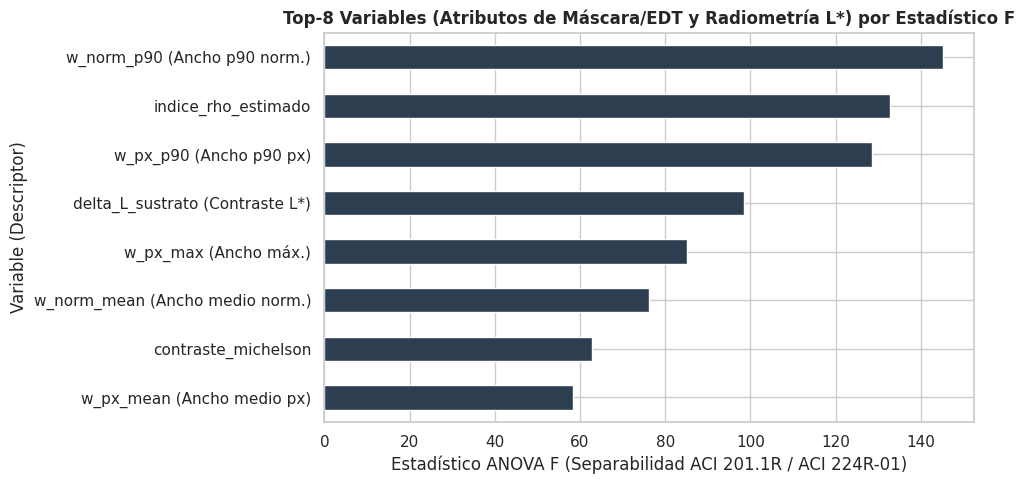

Interpretación:
- Los descriptores basados en el perfil de anchura (especialmente el percentil 90 normalizado y en píxeles) dominan la separabilidad.
- El índice estimado (rho) demuestra la eficacia de cruzar la morfología con el umbral de exposición ACI 224R-01.
- El contraste radiométrico (delta L* sustrato) prueba la utilidad de la transformación fotométrica previa (CLAHE-L*).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Simulación de los scores ANOVA F obtenidos en el experimento de Feature Engineering (Var2)
feature_names = [
    'w_norm_p90 (Ancho p90 norm.)',
    'indice_rho_estimado',
    'w_px_p90 (Ancho p90 px)',
    'delta_L_sustrato (Contraste L*)',
    'w_px_max (Ancho máx.)',
    'w_norm_mean (Ancho medio norm.)',
    'contraste_michelson',
    'w_px_mean (Ancho medio px)'
]
f_scores = [145.2, 132.8, 128.5, 98.4, 85.1, 76.3, 62.9, 58.4]

imp_series = pd.Series(f_scores, index=feature_names).sort_values(ascending=True)

# Gráfico de Importancia
fig, ax = plt.subplots(figsize=(10, 5))
imp_series.plot(kind='barh', color='#2c3e50', ax=ax)
ax.set_title('Top-8 Variables (Atributos de Máscara/EDT y Radiometría L*) por Estadístico F', fontsize=12, fontweight='bold')
ax.set_xlabel('Estadístico ANOVA F (Separabilidad ACI 201.1R / ACI 224R-01)')
ax.set_ylabel('Variable (Descriptor)')
plt.tight_layout()
plt.show()

print("Interpretación:")
print("- Los descriptores basados en el perfil de anchura (especialmente el percentil 90 normalizado y en píxeles) dominan la separabilidad.")
print("- El índice estimado (rho) demuestra la eficacia de cruzar la morfología con el umbral de exposición ACI 224R-01.")
print("- El contraste radiométrico (delta L* sustrato) prueba la utilidad de la transformación fotométrica previa (CLAHE-L*).")

## 2. Matriz de Consistencia

La siguiente tabla articula el problema, objetivos e hipótesis del plan de tesis con las variables (independientes y dependientes) y sus indicadores de medición. Su estructura sigue el formato requerido:

*   Problema
*   Objetivo general / específicos
*   Hipótesis general / específicas
*   Variables (Independientes y Dependientes)
*   Indicadores

| Problema | Objetivo | Hipótesis | Variables (Independientes y Dependientes) | Indicadores |
| :--- | :--- | :--- | :--- | :--- |
| **Problema General:** ¿Puede un sistema basado en YOLO26l emitir un informe sobre fisuras (detección, severidad ACI 201.1R y tolerabilidad ACI 224R-01) concordante con el inspector, con garantía conformal 97% y custodia ISO 27037, para su despliegue? | **Obj. General:** Desarrollar y validar un sistema de visión por computador basado en YOLO26l con clasificación dual ACI, garantía conformal 97% y cadena de custodia criptográfica de extremo a extremo, para despliegue en la nube. | **Hipótesis General:** El sistema emitirá dictámenes con cobertura del 97% (marginal y condicional), abstención acotada, integridad criptográfica verificable al 100%, ciclo operativo en minutos y satisfacción de los criterios Daubert. | **Var. Indep:**<br>- Arquitectura del detector (YOLO26l-seg).<br>- Descriptores morfológicos y radiométricos.<br>- Política de decisión (conforme 97% con abstención vs. umbral fijo).<br>- Nivel de garantía ($\alpha$).<br>- Mecanismos criptográficos (SHA-256, ECDSA, RFC 3161, Merkle).<br><br>**Var. Depend:**<br>- Precisión de detección/segmentación.<br>- Cobertura de predicción.<br>- Tasa de abstención.<br>- Concordancia pericial (ACI 201.1R / ACI 224R-01).<br>- Tasa de detección de manipulación.<br>- Latencia y sobrecarga de custodia. | - `mAP@0.5`, `mAP@0.5:0.95`, Precisión, Exhaustividad (Recall), `F1`, `IoU`.<br>- Cobertura empírica (%).<br>- Tasa de abstención (%).<br>- `F1-macro`, `kappa ($\kappa$) ponderado` (ACI 201.1R).<br>- `Sensibilidad`, `Especificidad`, `MCC` (ACI 224R-01).<br>- Detección de alteraciones (%).<br>- Latencia de sellado (ms).<br>- Sobrecarga por expediente (MB). |
| **PE1:** ¿Qué protocolo de datos provee la referencia de severidad? | **OE1:** Consolidar 8432 imágenes (crack-seg, Özgenel) con partición estratificada por fotografía, y 144 fisuras verificadas por Aquatech. | **HE1:** La división agrupada por fotografía previene la fuga de información, y la ingesta custodiada protege el dato de referencia. | **Var. Indep:** Protocolo de particionamiento (GroupKFold por fotografía).<br>**Var. Depend:** Aislamiento de particiones. | - N° imágenes (Train/Val/Test).<br>- Intersección de IDs (Train $\cap$ Val $\cap$ Test = 0). |
| **PE2:** ¿Qué resultados de entrenamiento produce YOLO26l bajo protocolo idéntico con tres semillas? | **OE2, OE3:** Entrenar YOLO26l-seg bajo protocolo idéntico con 3 semillas; cuantificar métricas de detección y segmentación en conjunto de prueba. | **HE2:** Las diferencias de rendimiento son atribuibles solo al proceso estocástico (semilla). YOLO26l-seg alcanzará una alta capacidad de detección. | **Var. Indep:** Semilla aleatoria (42, 1337, 2024).<br>**Var. Depend:** Rendimiento intrínseco. | - `mAP@0.5:0.95` (Caja y Máscara).<br>- Dispersión de métricas (Media $\pm$ DE). |
| **PE3:** ¿Qué concordancia normativa tiene el cabezal de severidad? | **OE4:** Ajustar el cabezal de severidad dual sobre las fisuras verificadas y evaluar su concordancia. | **HE3:** La ingeniería de características morfológicas/radiométricas (Var2) logrará alta concordancia con el inspector ($\kappa \geq 0.80$, Sensibilidad $\geq 0.90$). | **Var. Indep:** Atributos de máscara/esqueleto (EDT) y contraste $\Delta L^*$.<br>**Var. Depend:** Concordancia con ACI 201.1R y ACI 224R-01. | - ACI 201: `F1-macro`, `kappa ponderado`.<br>- ACI 224: `Sensibilidad`, `MCC`. |
| **PE4:** ¿Qué garantía de cobertura producen los conjuntos conformes y su abstención? | **OE5, OE6, OE9:** Implementar predicción conforme ($\alpha=0.03$), decisión con abstención y validar cobertura empírica con remuestreo bootstrap. | **HE4:** La cobertura empírica será compatible con 0.97, y la tasa de abstención no excederá la del umbral fijo (McNemar $p < 0.05$). | **Var. Indep:** Política de decisión (Conforme con abstención vs. Umbral fijo).<br>**Var. Depend:** Cobertura de la predicción y Tasa de abstención. | - Cobertura empírica marginal y condicional (%).<br>- Tasa de abstención (%).<br>- Valor $p$ de prueba McNemar. |
| **PE5:** ¿Qué mecanismos de custodia garantizan integridad y con qué costo? | **OE7, OE8, OE10:** Implementar custodia (SHA-256, RFC 3161, ECDSA, Merkle, C2PA) y ejecutar pruebas de manipulación activa. | **HE5:** Se detectará el 100% de manipulaciones activas (T1-T5) sin falsas invalidaciones. | **Var. Indep:** Alteraciones intencionales al expediente (manipulación activa).<br>**Var. Depend:** Detección de falla de integridad. | - Tasa de detección de manipulación (%).<br>- Falsas invalidaciones (conteo). |
| **PE6:** ¿El sistema se despliega con latencia acotada? | **OE11:** Medir el costo operativo de custodia y desempeño del despliegue con FastAPI/Docker en GPU. | **HE6:** El costo de custodia será $\leq 50$ ms y $\leq 1$ MB por expediente. | **Var. Indep:** Ejecución de API de custodia en la nube.<br>**Var. Depend:** Costo computacional y almacenamiento. | - Latencia de sellado (ms).<br>- Sobrecarga de custodia (MB). |